# 00 · nanoGPT 全景：源码地图与张量流

**Source audit:** [karpathy/nanoGPT](https://github.com/karpathy/nanoGPT/tree/3adf61e154c3fe3fca428ad6bc3818b27a3b8291) at `3adf61e154c3`; relevant files: `model.py`, `train.py`, `sample.py`, `data/shakespeare_char/prepare.py`, `config/train_shakespeare_char.py`.

**Scope:** The notebook uses a small **educational adaptation** (`nanogpt_edu.py`) consistent with the original architecture, not a verbatim copy of the full upstream training program. No pretrained weights, external datasets, downloads, distributed GPUs, or performance reproduction are claimed. Figures and prints are generated by real local CPU executions. The project's README has marked nanoGPT deprecated since Nov 2025 and points to nanochat.

## 这节要解决什么？

nanoGPT 将模型、训练、采样清晰地分成 `model.py`、`train.py`、`sample.py`。在小机器上先理解 **tensor shape**，再研究训练速度，效率更高。

主要符号：`B` = batch size，`T` = token sequence length，`C` = embedding dimension，`V` = vocabulary size。模型最终输出每个位置的下一个 token 概率分布。

In [1]:
from pathlib import Path
import sys, torch, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
# Compatible with starting Jupyter from the notebook directory OR repository root.
P = Path.cwd().resolve()
ROOT = P if (P / 'nanogpt_edu.py').exists() else P.parent
if not (ROOT / 'nanogpt_edu.py').exists():
    raise RuntimeError('Open this notebook from tutorials/nanogpt/notebooks or the tutorials/nanogpt directory')
sys.path.insert(0, str(ROOT))
from nanogpt_edu import GPTConfig, GPT, char_dataset, get_batch, training_text, lr_schedule, parameter_groups
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(min(2, torch.get_num_threads()))
torch.manual_seed(42); np.random.seed(42)
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| CPU tutorial', '| path:', ROOT)

Python: 3.13.5 | PyTorch: 2.10.0+cpu | CPU tutorial | path: /mnt/notebook-builder/tutorials/nanogpt


tokens: (2, 10) token embeddings: (2, 10, 32) position embeddings: (10, 32)
logits: (2, 10, 32) P(next token): (2, 10, 32)


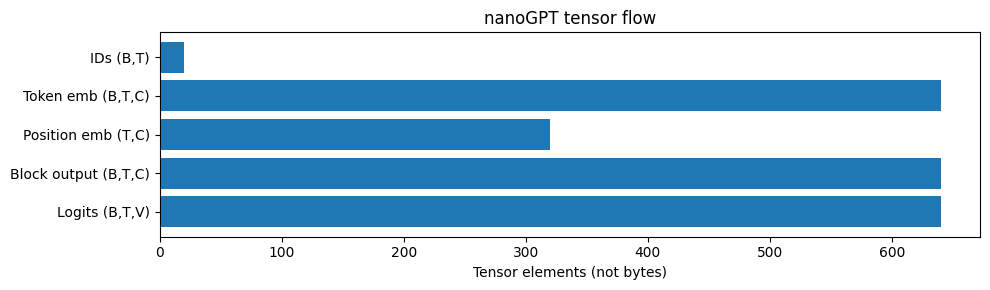

In [2]:
cfg = GPTConfig(vocab_size=32, block_size=16, n_layer=2, n_head=2, n_embd=32)
model = GPT(cfg).eval()
ids = torch.randint(0, cfg.vocab_size, (2, 10))
with torch.no_grad():
    tok = model.transformer.wte(ids)
    pos = model.transformer.wpe(torch.arange(ids.size(1)))
    logits, _ = model(ids, targets=ids)
print('tokens:', tuple(ids.shape), 'token embeddings:', tuple(tok.shape), 'position embeddings:', tuple(pos.shape))
print('logits:', tuple(logits.shape), 'P(next token):', tuple(logits.softmax(-1).shape))
assert logits.shape == (2, 10, 32)
fig, ax = plt.subplots(figsize=(10, 3))
names = ['IDs (B,T)', 'Token emb (B,T,C)', 'Position emb (T,C)', 'Block output (B,T,C)', 'Logits (B,T,V)']
width = [ids.numel(), tok.numel(), pos.numel(), tok.numel(), logits.numel()]
ax.barh(names[::-1], width[::-1]); ax.set_xlabel('Tensor elements (not bytes)')
ax.set_title('nanoGPT tensor flow'); fig.tight_layout()
fig.savefig(FIG / '00_tensor_flow.png', dpi=130); display(fig); plt.close(fig)

Unique trainable parameters: 27008
Breakdown: {'token embeddings (tied LM head)': 1024, 'position embeddings': 512, 'transformer blocks': 25408, 'final layer norm': 64}


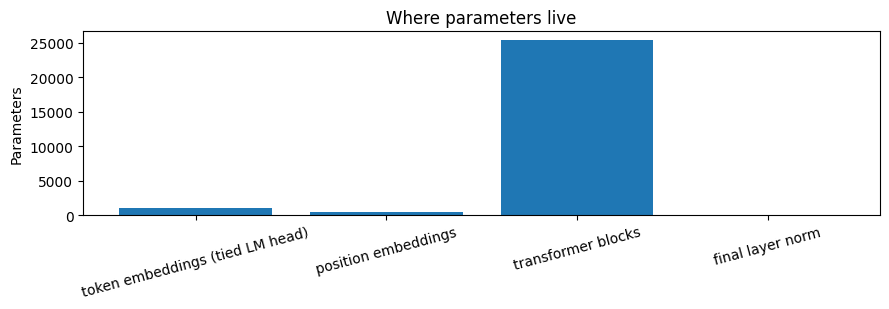

In [3]:
groups = {
  'token embeddings (tied LM head)': model.transformer.wte.weight.numel(),
  'position embeddings': model.transformer.wpe.weight.numel(),
  'transformer blocks': sum(p.numel() for b in model.transformer.h for p in b.parameters()),
  'final layer norm': sum(p.numel() for p in model.transformer.ln_f.parameters()),
}
print('Unique trainable parameters:', sum(p.numel() for p in model.parameters()))
print('Breakdown:', groups)
assert sum(groups.values()) == sum(p.numel() for p in model.parameters())
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(list(groups), list(groups.values())); ax.tick_params(axis='x', labelrotation=15)
ax.set_ylabel('Parameters'); ax.set_title('Where parameters live'); fig.tight_layout()
fig.savefig(FIG / '00_parameters.png', dpi=130); display(fig); plt.close(fig)

### 动手练习

1. 将 `n_embd` 改为 64，观察张量和参数规模如何变化。
2. 思考为什么输出 logits 的最后一维是 `V` 而不是 `C`。

**检查点：** 明确这张图只是各张量元素个数，不代表真实显存峰值，因为实际计算还存在梯度和中间激活。